In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

In [2]:
text = """
Artificial intelligence is changing the world.
Machine learning is a part of artificial intelligence.
Deep learning uses neural networks.
Python is a popular programming language.
Machine learning helps computers learn from data.
"""

In [3]:
sentences = re.split(r'[.!?]+', text.lower())

data = [re.sub(r'[^a-z ]', '', s).split()
        for s in sentences if s.strip()]

print(data)

[['artificial', 'intelligence', 'is', 'changing', 'the', 'world'], ['machine', 'learning', 'is', 'a', 'part', 'of', 'artificial', 'intelligence'], ['deep', 'learning', 'uses', 'neural', 'networks'], ['python', 'is', 'a', 'popular', 'programming', 'language'], ['machine', 'learning', 'helps', 'computers', 'learn', 'from', 'data']]


In [4]:
model = Word2Vec(data,vector_size=50,window=2, min_count=1,sg=0,epochs=100)
print(model.wv.key_to_index)

{'learning': 0, 'is': 1, 'a': 2, 'machine': 3, 'intelligence': 4, 'artificial': 5, 'data': 6, 'from': 7, 'learn': 8, 'computers': 9, 'helps': 10, 'language': 11, 'programming': 12, 'popular': 13, 'python': 14, 'networks': 15, 'neural': 16, 'uses': 17, 'deep': 18, 'of': 19, 'part': 20, 'world': 21, 'the': 22, 'changing': 23}


In [5]:
word = 'artificial'
similar_words = model.wv.most_similar(word)
for x in similar_words:
    print(x)

('popular', 0.3158593475818634)
('uses', 0.2795974910259247)
('computers', 0.2284592092037201)
('changing', 0.21741239726543427)
('language', 0.20531731843948364)
('data', 0.18824683129787445)
('intelligence', 0.11222910135984421)
('programming', 0.10834570229053497)
('python', 0.09245501458644867)
('of', 0.0433625802397728)


In [6]:
dat = []

for sentence in data:
    for i in range(2, len(sentence)-2):
        context = sentence[i-2:i] + sentence[i+1:i+3]
        target = sentence[i]
        dat.append((context, target))

print(dat)

[(['artificial', 'intelligence', 'changing', 'the'], 'is'), (['intelligence', 'is', 'the', 'world'], 'changing'), (['machine', 'learning', 'a', 'part'], 'is'), (['learning', 'is', 'part', 'of'], 'a'), (['is', 'a', 'of', 'artificial'], 'part'), (['a', 'part', 'artificial', 'intelligence'], 'of'), (['deep', 'learning', 'neural', 'networks'], 'uses'), (['python', 'is', 'popular', 'programming'], 'a'), (['is', 'a', 'programming', 'language'], 'popular'), (['machine', 'learning', 'computers', 'learn'], 'helps'), (['learning', 'helps', 'learn', 'from'], 'computers'), (['helps', 'computers', 'from', 'data'], 'learn')]


In [7]:
result = model.predict_output_word(dat[0][0], topn=5)

print("Context Words:", dat[0][0])
print("Predicted Words:")

for word, score in result:
    print(word, ":", round(score, 4))

Context Words: ['artificial', 'intelligence', 'changing', 'the']
Predicted Words:
world : 0.0417
the : 0.0417
deep : 0.0417
of : 0.0417
programming : 0.0417


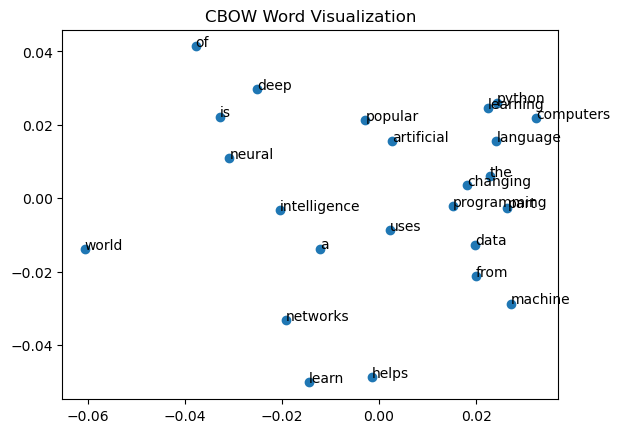

In [8]:
words = list(model.wv.index_to_key)
pca = PCA(n_components=2)
points = pca.fit_transform(model.wv[words])

plt.scatter(points[:,0], points[:,1])

for i, word in enumerate(words):
    plt.annotate(word, points[i])

plt.title("CBOW Word Visualization")
plt.show()